# Baseline 2 — ConvNeXt-Tiny (CN01): Stage 2 Fine-Tuning

**COS30082 | Out-of-Distribution Plant Disease Identification**  
**Architecture:** One shared ConvNeXt-Tiny V1 backbone with separate Crop (55) and Disease (175) heads.

In Stage 1, the best CN01 model was selected using development **Composition Harmonic Mean** (Epoch 15). This notebook continues **that checkpoint** on the union of the original 8,000 training images. We keep a predetermined 10-epoch schedule with lower learning rates, then save **Epoch 10** as the final checkpoint.

The purpose of Stage 2 is to use all available original training data *after* selecting the development settings. The old seen/unseen validation partitions now belong to training, so **they are no longer independent validation sets**.

**Notebook order:** setup → verify data/checkpoint → fixed configuration → DataLoader check → fine-tune → training curves and protocol lock. The Official Test is in a **separate notebook**, `convnext_cn01_official_test.ipynb`.

> Stage 2 only: this notebook does not access any Official Test images or labels. No fabricated outputs are included. Save the executed notebook (with real outputs) for GitHub.

## 1. Setup

Open this notebook from `Baseline2/notebooks/convnext/` in VS Code and select the same CUDA-enabled `.venv` used for CN01. The code reuses `model_convnext.py`, `evaluate.py` and `convnext_cn01_utils.py`; no new Python helper is required.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, copy, time, math, gc, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
from torch.utils.data import DataLoader

start = Path(os.environ.get('B2_PROJECT_ROOT', Path.cwd())).expanduser().resolve()
PROJECT_DIR = next((p for p in (start, *start.parents)
                    if (p/'evaluate.py').is_file() and (p/'splits_v2').is_dir()), None)
if PROJECT_DIR is None:
    PROJECT_DIR = Path(r'C:\AML\ML_Project\Baseline2')
if not (PROJECT_DIR/'evaluate.py').is_file():
    raise FileNotFoundError('Open the notebook within Baseline2, or set B2_PROJECT_ROOT to your project folder.')
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from evaluate import (DPDDataset, make_candidates, require_candidate_coverage,
                      evaluate_loader, generalisation_metrics, harmonic_mean,
                      read_metadata, validate_development_splits, image_paths,
                      _save_predictions, synthetic_self_test)
from model_convnext import load_convnext_checkpoint
from convnext_cn01_utils import (EXPECTED_SPLIT_HASHES, find_training_images,
                                  training_transform, evaluation_transform,
                                  train_one_epoch, seed_everything,
                                  environment_details, atomic_save, atomic_json,
                                  _capture_random_state, _restore_random_state)

In [2]:
# CHANGE ONLY THIS PATH IF YOUR ORIGINAL IMAGES LIVE SOMEWHERE ELSE.
IMAGE_ROOT = find_training_images(PROJECT_DIR)
SOURCE_CKPT = PROJECT_DIR/'outputs'/'convnext_cn01'/'best_development.pt'
STAGE2_DIR = PROJECT_DIR/'outputs'/'convnext_cn01_stage2'
FINAL_CKPT = STAGE2_DIR/'final_epoch10.pt'
OFFICIAL_DIR = PROJECT_DIR/'outputs'/'convnext_cn01_official_test'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Project:', PROJECT_DIR)
print('Training image root:', IMAGE_ROOT)
print('CN01 Stage 1 checkpoint:', SOURCE_CKPT)
print('Stage 2 outputs:', STAGE2_DIR)
print('GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'NOT AVAILABLE')
print('PyTorch:', torch.__version__)
assert SOURCE_CKPT.is_file(), 'Missing completed CN01 Stage 1 best_development.pt'

Project: C:\AML\ML_Project\Baseline2
Training image root: C:\AML\ML_Project\DPD_Small_dataset
CN01 Stage 1 checkpoint: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01\best_development.pt
Stage 2 outputs: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01_stage2
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch: 2.11.0+cu128


## 2. Training data and Stage 1 checkpoint

Before training, verify that the source is **CN01 Epoch 15**, not CN02. The three fixed development metadata files must contain 6,905 / 695 / 400 images with unchanged SHA-256 hashes. Stage 2 merges them back into the original **8,000 training images**. This step reads only original training metadata and images.

In [3]:
synthetic_self_test()
frames, split_report = validate_development_splits(PROJECT_DIR/'splits_v2')
assert split_report['sha256'] == EXPECTED_SPLIT_HASHES, 'Development metadata changed from your CN01 experiment.'
assert {k: len(v) for k,v in frames.items()} == {'train_fit':6905,'val_seen':695,'val_unseen':400}
full_frame = pd.concat([frames[k] for k in ('train_fit','val_seen','val_unseen')], ignore_index=True)
assert len(full_frame) == 8000 and full_frame.filename.is_unique

source_sha256 = hashlib.sha256(SOURCE_CKPT.read_bytes()).hexdigest()
source_payload = torch.load(SOURCE_CKPT, map_location='cpu', weights_only=True)
s1 = source_payload['config']
assert source_payload['stage'] == 1
assert source_payload['epoch'] == 15, 'Expected selected CN01 Epoch 15. Stop and check the file before continuing.'
assert (s1['experiment_id'],s1['backbone'],s1['pretrained_weights']) == ('convnext_cn01','convnext_tiny','IMAGENET1K_V1')
assert (s1['crop_classes'],s1['disease_classes']) == (55,175)
assert (float(s1['crop_loss_weight']),float(s1['disease_loss_weight'])) == (1.0,1.0)
assert s1['candidate_mode'] == 'all_pairs' and s1['training_sampling'] == 'natural_shuffle'
assert source_payload['development_split']['sha256'] == split_report['sha256']

candidates = make_candidates('all_pairs')
assert candidates.shape == (9625,2)
assert torch.equal(torch.as_tensor(source_payload['candidate_pairs'],dtype=torch.long), candidates), 'Different candidate pair ordering'
require_candidate_coverage(candidates, list(frames.values()))
assert len(image_paths(full_frame, IMAGE_ROOT)) == 8000, 'Training images missing or mislocated.'

print('Stage 1 selected epoch:', source_payload['epoch'])
print('Source SHA256:', source_sha256)
print('Source best development HM:', f"{source_payload['best_metrics']['composition_harmonic_mean']:.2%}")
print('Full original training images:',len(full_frame))
print('Candidates:',len(candidates))
print('Development split hashes: MATCH; Official Test not accessed.')
display(pd.DataFrame({'partition':list(frames),'images':[len(frames[k]) for k in frames]}))

Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
Stage 1 selected epoch: 15
Source SHA256: 08fe9e263d7c6c1e21d75a5d36d4f5b3d30e04f63d799abc666b9d8662effce5
Source best development HM: 7.60%
Full original training images: 8000
Candidates: 9625
Development split hashes: MATCH; Official Test not accessed.


,partition,images
0,train_fit,6905
1,val_seen,695
2,val_unseen,400


## 3. Fixed Stage 2 training configuration

We continue full-model fine-tuning (no frozen backbone) from CN01's selected checkpoint. Compared with Stage 1, learning rates are reduced by 10×. We retain ImageNet normalization, augmentation, equal crop/disease losses, and an effective batch size of 16 (microbatch 8 × gradient accumulation 2). **Two Windows DataLoader workers**, prefetching and pinned memory may make image loading faster; actual speed depends on CPU/storage. Worker count is recorded as an implementation difference from Stage 1.

We do not tune any settings using Official Test outcomes.

In [4]:
STAGE2_EPOCHS = 10
STAGE2_BACKBONE_LR = 1e-6
STAGE2_HEAD_LR = 1e-4
STAGE2_WEIGHT_DECAY = 1e-3
STAGE2_NUM_WORKERS = 2  # Windows: reduce to 0 before the FIRST run if multiprocessing fails.

stage2_train_config = copy.deepcopy(s1)
stage2_train_config.update({
    'stage': 2,
    'additional_epochs': STAGE2_EPOCHS,
    'backbone_lr': STAGE2_BACKBONE_LR,
    'head_lr': STAGE2_HEAD_LR,
    'weight_decay': STAGE2_WEIGHT_DECAY,
    'num_workers': STAGE2_NUM_WORKERS,
    'checkpoint_selection': 'fixed_final_epoch_10',
    'validation_used': False,
    'training_images': 8000,
})
assert float(stage2_train_config['crop_loss_weight']) == float(stage2_train_config['disease_loss_weight']) == 1.0
assert (stage2_train_config['batch_size'] * stage2_train_config['gradient_accumulation_steps']) == 16
assert STAGE2_BACKBONE_LR < s1['backbone_lr'] and STAGE2_HEAD_LR < s1['head_lr']

STAGE2_PLAN = {
    'experiment': 'B2 ConvNeXt CN01 Stage 2 full-data continuation',
    'source_checkpoint': str(SOURCE_CKPT),
    'source_checkpoint_sha256': source_sha256,
    'source_stage1_epoch': int(source_payload['epoch']),
    'source_development_split_sha256': split_report['sha256'],
    'config': stage2_train_config,
    'final_selection': 'fixed_last_epoch_10_before_official_test',
    'candidate_count': 9625,
    'official_data_used_for_training_or_selection': False,
}
print('Fixed Stage 2 plan:')
display(pd.DataFrame([{
    'epochs': STAGE2_EPOCHS,
    'backbone_lr': STAGE2_BACKBONE_LR,
    'head_lr': STAGE2_HEAD_LR,
    'weight_decay': STAGE2_WEIGHT_DECAY,
    'microbatch': stage2_train_config['batch_size'],
    'grad_accum': stage2_train_config['gradient_accumulation_steps'],
    'workers': STAGE2_NUM_WORKERS,
    'final_checkpoint': 'Epoch 10',
}]))

Fixed Stage 2 plan:


,epochs,backbone_lr,head_lr,weight_decay,microbatch,grad_accum,workers,final_checkpoint
0,10,0.000001,0.0001,0.001,8,2,2,Epoch 10


## 4. Prepare the GPU training loop

The DataLoader uses `num_workers=2`, `persistent_workers=True`, `prefetch_factor=2` and pinned memory on CUDA. These settings do not change the labels or composition scoring, but parallel workers can produce a different augmentation random sequence from Stage 1. A per-epoch checkpoint supports recovery after an interruption.

In [5]:
def make_full_train_loader(config):
    dataset = DPDDataset(full_frame, IMAGE_ROOT, training_transform(config))
    workers = int(config['num_workers'])
    kw = dict(batch_size=int(config['batch_size']), shuffle=True, drop_last=False,
              num_workers=workers, pin_memory=True,
              generator=torch.Generator().manual_seed(int(config['seed'])))
    if workers:
        kw.update(prefetch_factor=2, persistent_workers=True)
    return DataLoader(dataset, **kw)


def run_stage2(*, resume=False):
    if DEVICE.type != 'cuda':
        raise RuntimeError('CUDA is required for Stage 2; do not accidentally train 10 epochs on CPU.')
    if not resume and STAGE2_DIR.exists():
        raise FileExistsError(f'{STAGE2_DIR} exists. Never overwrite a completed/partial Stage 2 run.')
    if resume and not (STAGE2_DIR/'last_training.pt').is_file():
        raise FileNotFoundError('Cannot resume: last_training.pt not found.')
    if resume and FINAL_CKPT.exists():
        raise FileExistsError('Final Stage 2 checkpoint already exists. Do not retrain.')

    seed_everything(int(stage2_train_config['seed']))
    loader = make_full_train_loader(stage2_train_config)
    model, _ = load_convnext_checkpoint(SOURCE_CKPT, DEVICE)
    optimizer = torch.optim.AdamW(model.parameter_groups(STAGE2_BACKBONE_LR, STAGE2_HEAD_LR),
                                  weight_decay=STAGE2_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STAGE2_EPOCHS)
    scaler = torch.amp.GradScaler('cuda', enabled=bool(stage2_train_config['amp']))
    start_epoch, history = 1, []
    if resume:
        status = json.loads((STAGE2_DIR/'run_status.json').read_text(encoding='utf8'))
        if status.get('status') == 'complete':
            raise FileExistsError('Stage 2 marked complete. Do not resume.')
        plan = json.loads((STAGE2_DIR/'stage2_plan.json').read_text(encoding='utf8'))
        if plan != STAGE2_PLAN:
            raise ValueError('Stage 2 resume plan differs from the original run. STOP.')
        state = torch.load(STAGE2_DIR/'last_training.pt', map_location='cpu', weights_only=True)
        if state['source_checkpoint_sha256'] != source_sha256 or state['config'] != stage2_train_config:
            raise ValueError('Checkpoint/source/config mismatch. STOP.')
        model.load_state_dict(state['model_state'], strict=True)
        optimizer.load_state_dict(state['optimizer_state'])
        scheduler.load_state_dict(state['scheduler_state'])
        scaler.load_state_dict(state['scaler_state'])
        history = list(state['history'])
        start_epoch = int(state['epoch'])+1
        assert len(history) == start_epoch-1
        _restore_random_state(state['rng_state'], loader)
        print('RESUMING Stage 2 at epoch', start_epoch)
    else:
        STAGE2_DIR.mkdir(parents=True, exist_ok=False)
        atomic_json(STAGE2_PLAN, STAGE2_DIR/'stage2_plan.json')
        atomic_json({'status':'training','last_epoch':0}, STAGE2_DIR/'run_status.json')

    try:
        for epoch in range(start_epoch, STAGE2_EPOCHS+1):
            started = time.perf_counter()
            lr_backbone, lr_head = [float(g['lr']) for g in optimizer.param_groups]
            losses = train_one_epoch(model, loader, optimizer, scaler, DEVICE, stage2_train_config)
            if not all(math.isfinite(v) for v in losses.values()):
                raise RuntimeError('Non-finite training loss')
            scheduler.step()
            row = {'additional_epoch':epoch, 'backbone_lr':lr_backbone, 'head_lr':lr_head,
                   **losses, 'epoch_seconds':time.perf_counter()-started}
            history.append(row)
            atomic_save({'stage':2,'epoch':epoch,'config':copy.deepcopy(stage2_train_config),
                         'source_checkpoint_sha256':source_sha256,
                         'model_state':model.state_dict(),
                         'optimizer_state':optimizer.state_dict(),
                         'scheduler_state':scheduler.state_dict(),
                         'scaler_state':scaler.state_dict(),
                         'rng_state':_capture_random_state(loader),
                         'history':history}, STAGE2_DIR/'last_training.pt')
            pd.DataFrame(history).to_csv(STAGE2_DIR/'full_data_history.csv',index=False)
            atomic_json({'status':'training','last_epoch':epoch},STAGE2_DIR/'run_status.json')
            print(f'Stage 2 Epoch {epoch:02d}/{STAGE2_EPOCHS} | '
                  f'train loss={losses["total_loss"]:.4f} | '
                  f'crop={losses["crop_loss"]:.4f} | '
                  f'disease={losses["disease_loss"]:.4f}',flush=True)

        assert len(history)==STAGE2_EPOCHS
        final = {'stage':2,'epoch':STAGE2_EPOCHS,'full_training_count':8000,
                 'model_state':model.state_dict(), 'config':copy.deepcopy(stage2_train_config),
                 'candidate_pairs':candidates.tolist(),
                 'class_mappings':source_payload['class_mappings'],
                 'composition_mapping':source_payload['composition_mapping'],
                 'development_split':split_report,
                 'parent_checkpoint':str(SOURCE_CKPT),
                 'parent_checkpoint_sha256':source_sha256,
                 'parent_best_epoch':int(source_payload['epoch']),
                 'selection':'fixed_final_epoch_10',
                 'former_validation_is_independent':False,
                 'environment':environment_details(DEVICE)}
        atomic_save(final, FINAL_CKPT)
        atomic_json({'status':'complete','last_epoch':STAGE2_EPOCHS,
                     'final_checkpoint':str(FINAL_CKPT)},STAGE2_DIR/'run_status.json')
        print('Stage 2 COMPLETE. Final checkpoint:',FINAL_CKPT)
        print('No Official Test files have been accessed.')
    finally:
        del model, loader
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    return STAGE2_DIR

### Check DataLoader workers before training

This short test actually loads one minibatch using two workers. If Windows reports a worker-spawn error, **stop before training**. You may change `STAGE2_NUM_WORKERS` in Section 3 to `0` *before the first run* and rerun this check (training protocol must record the setting). Do not change the configuration in the middle of an active Stage 2 run.

In [6]:
WORKER_PREFLIGHT = True
if WORKER_PREFLIGHT:
    worker_loader = make_full_train_loader(stage2_train_config)
    first_batch = next(iter(worker_loader))
    assert first_batch['image'].shape[1:] == (3, 224, 224)
    print('DataLoader check PASSED: workers =', worker_loader.num_workers,
          '| image batch =', tuple(first_batch['image'].shape))
    del worker_loader, first_batch
    gc.collect()
else:
    print('DataLoader check skipped.')

DataLoader check PASSED: workers = 2 | image batch = (8, 3, 224, 224)


## 5. Fine-tune on all 8,000 training images

This step needs your **RTX 4050 GPU**. After Sections 1–4 pass, set `RUN_STAGE2=True` and run **this cell only**. It trains exactly 10 additional epochs, writes per-epoch recovery checkpoints, and saves `outputs/convnext_cn01_stage2/final_epoch10.pt`. Do **not** use the Official Test to select another epoch.

For an interrupted run, restart the kernel, rerun Sections 1–4 without changing settings, and set `RESUME_STAGE2=True`. Worker-based augmentation after restarting may not be bit-for-bit identical; note any restart in the report.

Once complete, switch `RUN_STAGE2` back to `False` before saving this notebook for GitHub, so readers do not unintentionally repeat training.

In [7]:
RUN_STAGE2 = True  # Set True to START or RESUME training, after reviewing the fixed plan.
RESUME_STAGE2 = False  # True ONLY for recovering an interrupted Stage 2 run.
if RUN_STAGE2:
    run_stage2(resume=RESUME_STAGE2)
else:
    print('Stage 2 disabled. To train, review the plan and set RUN_STAGE2=True.')

Stage 2 Epoch 01/10 | train loss=0.6520 | crop=0.1802 | disease=0.4719
Stage 2 Epoch 02/10 | train loss=0.4121 | crop=0.1045 | disease=0.3077
Stage 2 Epoch 03/10 | train loss=0.3026 | crop=0.0760 | disease=0.2266
Stage 2 Epoch 04/10 | train loss=0.2525 | crop=0.0567 | disease=0.1958
Stage 2 Epoch 05/10 | train loss=0.2413 | crop=0.0517 | disease=0.1897
Stage 2 Epoch 06/10 | train loss=0.2154 | crop=0.0486 | disease=0.1668
Stage 2 Epoch 07/10 | train loss=0.2083 | crop=0.0475 | disease=0.1609
Stage 2 Epoch 08/10 | train loss=0.1946 | crop=0.0409 | disease=0.1537
Stage 2 Epoch 09/10 | train loss=0.1869 | crop=0.0425 | disease=0.1444
Stage 2 Epoch 10/10 | train loss=0.1886 | crop=0.0414 | disease=0.1473
Stage 2 COMPLETE. Final checkpoint: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01_stage2\final_epoch10.pt
No Official Test files have been accessed.


## 6. Training history and final evaluation protocol

The loss curves below use the **actual executed Stage 2 training history** (not validation accuracy). The protocol-lock file records the final Epoch 10 checkpoint and fixed inference rules **before** any Official Test is run. Execute this section after training finishes.

,additional_epoch,backbone_lr,head_lr,total_loss,crop_loss,disease_loss,epoch_seconds
0,1,0.0,0.00010,0.65205,0.18018,0.47187,102.79423
1,2,0.0,0.00010,0.41214,0.10448,0.30766,76.12968
2,3,0.0,0.00009,0.30261,0.07604,0.22657,83.20499
3,4,0.0,0.00008,0.25246,0.05671,0.19575,91.07009
4,5,0.0,0.00007,0.24131,0.05166,0.18965,76.03064
5,6,0.0,0.00005,0.21539,0.04862,0.16677,75.07984
6,7,0.0,0.00003,0.20834,0.04747,0.16087,77.20715
7,8,0.0,0.00002,0.19462,0.04095,0.15367,74.27993
8,9,0.0,0.00001,0.18691,0.04254,0.14437,74.48830
9,10,0.0,0.00000,0.18862,0.04135,0.14727,74.41967


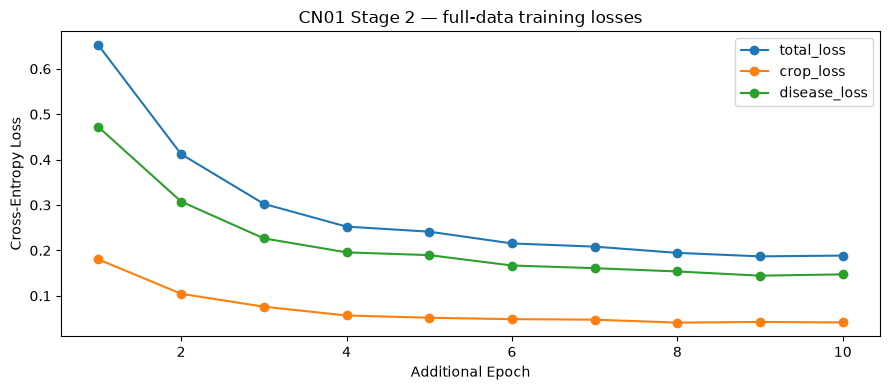

OFFICIAL PROTOCOL LOCKED (no test data accessed).
Final checkpoint SHA256: d09c20ed59cfc102b2c539c147f7f842ee4b250c9f781daab67fc322bc41afe8
Protocol file: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01_stage2\official_protocol_lock.json


In [8]:
if FINAL_CKPT.is_file():
    status = json.loads((STAGE2_DIR/'run_status.json').read_text(encoding='utf8'))
    assert status['status']=='complete'
    final_payload = torch.load(FINAL_CKPT,map_location='cpu',weights_only=True)
    assert (final_payload['stage'],final_payload['epoch'],final_payload['full_training_count'])==(2,10,8000)
    assert final_payload['parent_checkpoint_sha256']==source_sha256
    assert final_payload['selection']=='fixed_final_epoch_10'
    assert final_payload['config']==stage2_train_config
    assert final_payload['development_split']['sha256']==split_report['sha256']
    assert torch.equal(torch.as_tensor(final_payload['candidate_pairs'],dtype=torch.long),candidates)
    full_history = pd.read_csv(STAGE2_DIR/'full_data_history.csv')
    assert full_history.additional_epoch.tolist()==list(range(1,11))
    display(full_history.round(5))
    ax=full_history.plot(x='additional_epoch',y=['total_loss','crop_loss','disease_loss'],
                         marker='o',figsize=(9,4),title='CN01 Stage 2 — full-data training losses')
    ax.set(xlabel='Additional Epoch',ylabel='Cross-Entropy Loss')
    plt.tight_layout()
    plt.savefig(STAGE2_DIR/'full_data_training_curves.png',dpi=160)
    plt.show()
    final_sha256=hashlib.sha256(FINAL_CKPT.read_bytes()).hexdigest()
    evaluation_lock={
        'model':'B2 ConvNeXt CN01',
        'final_checkpoint':str(FINAL_CKPT),
        'final_checkpoint_sha256':final_sha256,
        'parent_checkpoint_sha256':source_sha256,
        'final_training_epoch':10,
        'full_training_images':8000,
        'source_stage1_epoch':15,
        'candidate_mode':'all_pairs',
        'candidate_count':9625,
        'candidate_order':'crop_id ascending outer; disease_id ascending inner',
        'scoring':'crop_log_softmax + disease_log_softmax',
        'gamma':0.0,
        'temperature':1.0,
        'test_time_augmentation':False,
        'resize':256,
        'resize_interpolation':'BILINEAR',
        'center_crop':224,
        'normalization':'ImageNet mean/std',
        'official_expected_seen':2000,
        'official_expected_unseen':1448,
        'metrics':['crop/disease/composition top1','crop/disease/composition top5','seen-unseen HM','confusion matrices'],
        'official_test_used_for_model_selection':False,
    }
    lock_path=STAGE2_DIR/'official_protocol_lock.json'
    if lock_path.exists():
        existing=json.loads(lock_path.read_text(encoding='utf8'))
        if existing!=evaluation_lock:
            raise ValueError('Existing Official Test protocol lock differs. STOP; do not change protocol.')
    else:
        atomic_json(evaluation_lock,lock_path)
    print('OFFICIAL PROTOCOL LOCKED (no test data accessed).')
    print('Final checkpoint SHA256:',final_sha256)
    print('Protocol file:', lock_path)
else:
    print('Stage 2 not complete yet. Finish Section 4 first. Official Test remains disabled.')

## 7. Discussion and limitations

**What was done.** We fine-tuned the same shared ConvNeXt-Tiny model from the selected Stage 1 Epoch 15 checkpoint on all original 8,000 training images, using a fixed additional 10-epoch schedule, AdamW and a cosine learning-rate schedule. Both classification heads are trained using Cross-Entropy and equal task weights.

**What the Stage 2 loss curve tells us.** A decreasing training loss indicates the model fits the combined training data more closely. It **does not** establish improved unseen composition generalisation, because the previous validation images are now included in training.

**What comes next.** After the final checkpoint and `official_protocol_lock.json` are saved, open `convnext_cn01_official_test.ipynb` for **one** final, predetermined evaluation. Include the resulting Top-1, Top-5, HM and confusion matrices in the report. Compare these with B1 **Official Test** metrics, not B1 development-validation metrics.

**Fairness limitations.** B1's independent task models may use a different Stage 2 checkpoint-selection method and optimizer grouping; our fixed final epoch avoids choosing checkpoints after observing Official Test. Therefore, B1/B2 differences cannot be attributed to architecture alone. The 2-worker DataLoader setting may alter random augmentation order relative to Stage 1. Earlier ResNet Official Test experience may have informed subsequent research decisions and should be acknowledged.